In [54]:
import os, locale
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import warnings
from collections import defaultdict
from IPython.display import display
from pathlib import Path

warnings.filterwarnings("ignore")
locale.setlocale(locale.LC_ALL, '')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

systemName = "XStore"

clientNodes = ["64.131.114.143", "64.131.114.144", "64.131.114.145", "64.131.114.146",
              "64.131.114.147", "64.131.114.148", "64.131.114.153", "64.131.114.154"]

# Top-level data dirs are Title-Case on disk; DB-prefixed subfolders (e.g. XSTORE_AGG_MIN_QUERY) stay upper-case
DB_LIST = ["XSTORE", "MONGODB", "INFLUXDB", "GRAPHITE"]
DB_DIR = {"XSTORE": "XStore", "MONGODB": "MongoDB", "INFLUXDB": "InfluxDB", "GRAPHITE": "Graphite"}
DB_LABEL = {"XSTORE": systemName, "MONGODB": "MongoDB", "INFLUXDB": "InfluxDB", "GRAPHITE": "Graphite"}
DB_COLOR = {"XSTORE": "tab:red", "MONGODB": "tab:green", "INFLUXDB": "tab:purple", "GRAPHITE": "tab:blue"}
DB_LINESTYLE = {"XSTORE": (0, (1, 1)), "MONGODB": "--", "INFLUXDB": "-.", "GRAPHITE": ":"}


def load_latency_data(db, workload_type, max_clients=64):
    """Read every per-client 'Time taken (ms)' CSV for a (db, workload) pair.
    Returns {Client-N: [mean latency across all N concurrent clients, per request]}.
    Row 0 of every CSV is dropped (connection warm-up sample).
    """
    base = f"{DB_DIR[db]}/{db}_{workload_type}"
    tiers = sorted(os.listdir(base), key=lambda x: int(x.split("-")[-1]))
    benchData = {}
    for tier in tiers:
        if int(tier.split("-")[1]) > max_clients:
            continue
        perClientLatency = []
        for node in os.listdir(f"{base}/{tier}"):
            nodeDir = f"{base}/{tier}/{node}"
            for csvFile in os.listdir(nodeDir):
                if csvFile.endswith(".csv"):
                    df = pd.read_csv(f"{nodeDir}/{csvFile}")
                    perClientLatency.append(df["Time taken (ms)"].tolist())
        rows = pd.DataFrame(zip(*perClientLatency))
        benchData[tier] = rows.mean(axis=1).tolist()[1:]
    return benchData


def load_sysstat_data(db, workload_type):
    """Read Node-0's cpuCleaned/memCleaned/ioCleaned.txt for every client tier of
    a (db, workload) pair. Returns {Client-N: DataFrame[CPU/Mem/IO]}.
    """
    base = f"{DB_DIR[db]}/{db}_{workload_type}"
    tiers = sorted(os.listdir(base), key=lambda x: int(x.split("-")[-1]))
    benchData = {}
    for tier in tiers:
        nodeDir = f"{base}/{tier}/Node-0"
        cpu = pd.read_csv(f"{nodeDir}/cpuCleaned.txt")
        cpu["CPU Utilization (%)"] = 100 - cpu["%idle"]
        mem = pd.read_csv(f"{nodeDir}/memCleaned.txt")
        mem["Memory Usage (GB)"] = mem["kbmemused"] / 1024 / 1024
        io = pd.read_csv(f"{nodeDir}/ioCleaned.txt")
        io["I/O Calls"] = io["tps"]
        df = pd.concat([cpu[["CPU Utilization (%)"]], mem[["Memory Usage (GB)"]], io[["I/O Calls"]]],
                        ignore_index=True, axis=1)
        df.columns = ["CPU Utilization (%)", "Memory Usage (GB)", "I/O Calls"]
        benchData[tier] = df
    return benchData


def set_box_color(bp, color):
    lineWidth = 1.1
    plt.setp(bp['boxes'], color=color, linewidth=lineWidth)
    plt.setp(bp['whiskers'], color=color, linewidth=lineWidth)
    plt.setp(bp['caps'], color=color, linewidth=lineWidth)
    plt.setp(bp['medians'], color='#003f5c', linewidth=lineWidth)


def list_files_recursively_os_walk(start_dir):
    """Recursively lists all file paths within the specified directory, grouped by Client-N tier."""
    file_paths = []
    for root, dirs, files in os.walk(start_dir):
        dirs[:] = [d for d in dirs if not d.startswith('.')]
        for file in files:
            file_paths.append(os.path.join(root, file))
    file_paths.sort(key=lambda x: int(x.split("/")[2].split("-")[1]))
    fileGroups = defaultdict(list)
    for p in file_paths:
        fileGroups[Path(p).parts[2]].append(p)
    return file_paths, fileGroups


# Backtester

In [38]:
def stackedBar(stopAtMultiple, dataDir, logScaleLeft=True, logScaleRight=False):
    """Backtester wall-clock time + aggregate throughput, one panel per DB.

    logScaleLeft:  log-scale the left axis (Total Time, seconds)
    logScaleRight: log-scale the right axis (Backtests per Hour)
    """
    colorMap = {systemName: "tab:red", "MongoDB": "tab:green", "InfluxDB": "tab:purple", "Graphite": "tab:blue",
               "CSV": "tab:orange", "Parquet": "tab:olive", "line": "#003f5c"}
    dbNames = {"XStore": "XStore", "MongoDB": "MongoDB", "InfluxDB": "InfluxDB", "Graphite": "Graphite", "CSV": "CSV", "Parquet": "Parquet"}

    numClients = [2**i for i in range(stopAtMultiple)]
    summary = {}
    timeSummary = {}
    allData = {}

    for db in dbNames:
        # Recursively list all files in this DB
        TargetFiles, FileGroups = list_files_recursively_os_walk(f"{dataDir}/{db.upper()}_BACKTEST")

        for ClientGroup in FileGroups:
            NClient = int(ClientGroup.split("-")[1])
            ClientFiles = FileGroups[ClientGroup]
            TotalTime = []

            for file in ClientFiles:
                with open(file, "r") as f:
                    content = f.readlines()
                    # Experiment failed
                    if len(content) < 12:
                        allData[f"{db}_{NClient}"] = [np.nan, np.nan]
                        continue
                    # Good experiment, in seconds
                    TotalTime.append(float(locale.atof(content[8].split(" ")[-1].replace("s", "").strip())))

            # Wall-clock time for the tier = slowest of the parallel nodes; aggregate throughput = total work / that time
            TotalTime = max(TotalTime)
            Throughput = (NClient * 3600) / TotalTime
            allData[f"{db}_{NClient}"] = [TotalTime, Throughput]
        x = np.arange(len(numClients))  # the label locations

    width = 0.6  # the width of the bars

    fig, axs = plt.subplots(1, 6, figsize=(20, 5), sharex=True, sharey=True, gridspec_kw={'hspace': 0, 'wspace': 0.05})
    secondaryAxes = []

    yIdx = 0
    for db in dbNames:
        currData = {"Total Time": [], "Throughput": []}
        for nClient in numClients:
            currData["Total Time"].append(allData[f"{db}_{nClient}"][0])
            currData["Throughput"].append(allData[f"{db}_{nClient}"][1])

        if db == "XStore":
            db = systemName

        axs[yIdx].bar(x, currData["Total Time"], width, color=colorMap[db])
        axs[yIdx].set_xticks(x, numClients, rotation_mode='anchor', ha='center', fontsize=10)
        axs[yIdx].tick_params(axis='y', labelsize=10.5)
        if logScaleLeft:
            axs[yIdx].set_yscale('log')

        axs[yIdx].set_title(f"{db}", color=colorMap[db], fontweight='bold', fontsize=13)
        axs[yIdx].grid(axis="y", which="major", linestyle="--", color="tab:gray")

        axes2 = axs[yIdx].twinx()
        if logScaleRight:
            axes2.set_yscale('log')
        if len(secondaryAxes) == 0:
            secondaryAxes.append(axes2)
        else:
            axes2.sharey(secondaryAxes[0])

        summary[db] = currData["Throughput"]
        timeSummary[db] = currData["Total Time"]

        axes2.plot(x, currData["Throughput"], marker='o', linestyle="--", color=colorMap["line"], markersize=5, alpha=1, linewidth=1.5)
        axes2.tick_params(axis='y', labelcolor=colorMap["line"])
        if yIdx != 5:
            axes2.yaxis.set_tick_params(labelcolor='none', labelsize=10.5)

        yIdx += 1

    fig.text(0.095, 0.5, "Time Taken (second)", va="center", rotation="vertical", fontweight='bold', fontsize=13)
    fig.text(0.925, 0.5, "Backtest per Hour", va="center", rotation=270, color=colorMap["line"], fontweight='bold', fontsize=13)
    fig.text(0.4725, 0.025, "Number of Client", va="center", fontweight='bold', fontsize=13)

    plt.axis('tight')
    fig.tight_layout(pad=0)
    plt.savefig(f"{systemName}_{dataDir.replace('/', '_')}.svg", format='svg', dpi=fig.dpi, bbox_inches='tight')
    plt.show()

    # --- Summary table: per-client-count throughput, plus overall AVG and speedup vs XStore ---
    # Speedup = how many times better XStore is (higher throughput = better): >1 means XStore is
    # faster by that factor, <1 means XStore is actually slower (by 1/x).
    statsTable = pd.DataFrame(summary, index=[f"Client-{n}" for n in numClients])
    statsTable.loc["AVG"] = statsTable.mean()
    statsTable.loc["Speedup (x)"] = statsTable.loc["AVG", systemName] / statsTable.loc["AVG"]

    # --- Time Taken (second) table: per-client-count wall-clock time, plus overall AVG and speedup vs XStore ---
    # Speedup here = other_avg_time / XStore_avg_time (lower time is better): >1 means XStore is
    # faster by that factor, <1 means XStore is actually slower (by 1/x).
    timeTable = pd.DataFrame(timeSummary, index=[f"Client-{n}" for n in numClients])
    timeTable.loc["AVG"] = timeTable.mean()
    timeTable.loc["Speedup (x)"] = timeTable.loc["AVG"] / timeTable.loc["AVG", systemName]

    return statsTable.round(2), timeTable.round(2)


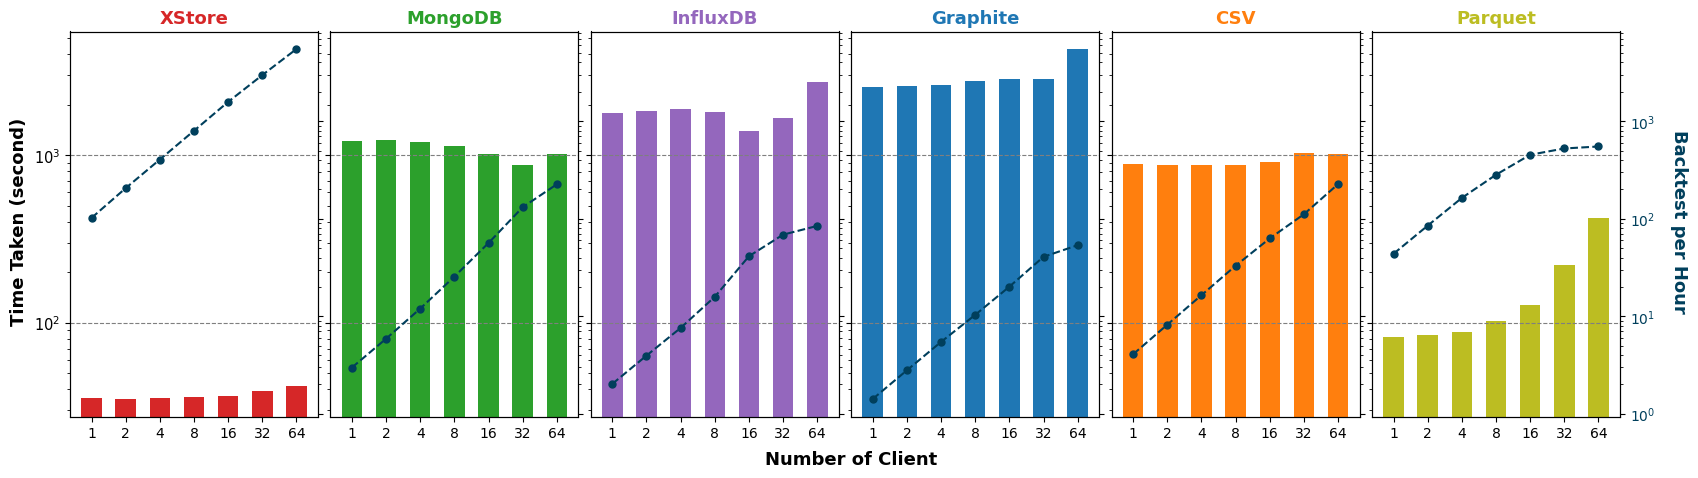

,XStore,MongoDB,InfluxDB,Graphite,CSV,Parquet
Client-1,101.93,2.98,2.03,1.42,4.08,43.72
Client-2,205.83,5.89,3.95,2.79,8.20,84.94
Client-4,404.72,12.00,7.60,5.46,16.46,163.41
Client-8,798.00,25.53,15.85,10.34,32.96,282.46
Client-16,"1,578.08",56.46,41.30,20.11,62.88,452.58
Client-32,"2,969.84",131.32,68.73,40.72,111.25,525.19
Client-64,"5,496.18",225.73,84.43,53.56,226.49,550.27
AVG,"1,650.66",65.70,31.98,19.20,66.05,300.37
Speedup (x),1.00,25.12,51.61,85.96,24.99,5.50


,XStore,MongoDB,InfluxDB,Graphite,CSV,Parquet
Client-1,35.32,"1,207.19","1,774.63","2,536.08",882.54,82.34
Client-2,34.98,"1,222.74","1,822.06","2,576.08",877.54,84.77
Client-4,35.58,"1,199.73","1,894.27","2,637.12",874.87,88.12
Client-8,36.09,"1,128.09","1,817.05","2,784.83",873.78,101.96
Client-16,36.50,"1,020.25","1,394.82","2,863.63",915.97,127.27
Client-32,38.79,877.26,"1,676.12","2,828.78","1,035.52",219.35
Client-64,41.92,"1,020.70","2,728.81","4,301.57","1,017.27",418.70
AVG,37.03,"1,096.57","1,872.54","2,932.58",925.36,160.36
Speedup (x),1.00,29.62,50.57,79.20,24.99,4.33


In [39]:
backtesterTable, backtesterTimeTable = stackedBar(7, "Backtester", logScaleRight=True)
display(backtesterTable)
display(backtesterTimeTable)


# Latency

In [47]:
def plotLatency(targetData, plotName, stopAtMultiple, clientNodes, logScale=False):
    lineWidth = 1.5
    lineAlpha = 1
    # Label offset is an axes-relative fraction; fewer columns means each axes is wider, so the
    # offset must shrink proportionally or the label drifts far from a single-column plot.
    yLabelCoords = [-0.05 * len(targetData), 0.5]
    numClients = [2**i for i in range(stopAtMultiple)]
    numClientLabels = [f"Client-{i}" for i in numClients]
    allData = {}

    for WORKLOAD_TYPE in targetData:
        temp = {}
        for db in DB_LIST:
            temp[db] = pd.DataFrame(load_latency_data(db, WORKLOAD_TYPE))
        allData[WORKLOAD_TYPE] = temp

    # Width matches the original per-N figures exactly: 7in for 1 workload, 12in for 4 (fit line through both).
    figWidth = 7 + (5 / 3) * (len(targetData) - 1)
    fig = plt.figure(figsize=(figWidth, 7))
    subFigs = fig.subfigures(2, 1, hspace=0.25)
    # squeeze=False keeps these indexable the same way whether targetData has 1 or many workloads
    axs = subFigs[0].subplots(1, len(targetData), squeeze=False)[0]
    axss = subFigs[1].subplots(3, len(targetData), squeeze=False)
    subFigs[1].subplots_adjust(hspace=0.1, wspace=0.2)

    latencyTables = {}
    for idx, workload in enumerate(allData):
        xstoreData = [allData[workload]["XSTORE"][i].tolist() for i in numClientLabels]
        mongoData = [allData[workload]["MONGODB"][i].tolist() for i in numClientLabels]
        influxData = [allData[workload]["INFLUXDB"][i].tolist() for i in numClientLabels]
        graphiteData = [allData[workload]["GRAPHITE"][i].tolist() for i in numClientLabels]

        xstorePlot = axs[idx].boxplot(xstoreData, positions=np.array(range(len(xstoreData)))*4.0-1.5*1, sym='', widths=0.6, patch_artist=True)
        mongoPlot = axs[idx].boxplot(mongoData, positions=np.array(range(len(mongoData)))*4.0-0.5*1, sym='', widths=0.6, patch_artist=True)
        influxPlot = axs[idx].boxplot(influxData, positions=np.array(range(len(influxData)))*4.0+0.5*1, sym='', widths=0.6, patch_artist=True)
        graphitePlot = axs[idx].boxplot(graphiteData, positions=np.array(range(len(graphiteData)))*4.0+1.5*1, sym='', widths=0.6, patch_artist=True)

        set_box_color(xstorePlot, DB_COLOR["XSTORE"])
        set_box_color(mongoPlot, DB_COLOR["MONGODB"])
        set_box_color(influxPlot, DB_COLOR["INFLUXDB"])
        set_box_color(graphitePlot, DB_COLOR["GRAPHITE"])

        # Labels & Legends
        if workload == "AGG_MIN_QUERY":
            title = "Analytical Queries (MIN)"
        else:
            s = workload.split('_')
            title = f"{s[1]} {s[0]} - {s[-1].replace('RAND', 'RND')}"
        axs[idx].set_title(title, fontweight="bold", fontsize=10)
        axs[idx].set_yscale('log')
        axs[idx].set_xticks(range(0, len(numClients) * 4, 4), numClients)
        axs[idx].set_xlabel(xlabel="Client", fontweight="bold", fontsize=8)
        axs[idx].grid(axis="y", which="major", linestyle="--", color="tab:gray")
        [axs[idx].axvspan(xmin=i, xmax=i+4, color="tab:gray", alpha=0.2) for i in [2, 10, 18]]

        # Per-client-tier mean latency table for this workload (Backtester-style: rows=Client-N, cols=DB)
        tierTable = pd.DataFrame({
            DB_LABEL["XSTORE"]: [sum(c) / len(c) for c in xstoreData],
            "MongoDB": [sum(c) / len(c) for c in mongoData],
            "InfluxDB": [sum(c) / len(c) for c in influxData],
            "Graphite": [sum(c) / len(c) for c in graphiteData],
        }, index=numClientLabels)
        tierTable.loc["AVG"] = tierTable.mean()
        # Speedup = how many times better XStore is (lower latency = better): >1 means XStore is
        # faster by that factor, <1 means XStore is actually slower (by 1/x).
        tierTable.loc["Speedup (x)"] = tierTable.loc["AVG"] / tierTable.loc["AVG", DB_LABEL["XSTORE"]]
        latencyTables[workload] = tierTable

    axs[0].set_ylabel(ylabel="Latency (ms)", fontweight="bold", fontsize=8)
    axs[0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])

    for ax in axs[1:]:
        ax.sharey(axs[0])
        ax.tick_params(labelleft=False)
    for ax in axs:
        ax.margins(x=0.2, y=0.05)

    # Sysstat (resource usage @ Client-64), one column per workload
    allData = {}
    for WORKLOAD_TYPE in targetData:
        temp = {}
        for db in DB_LIST:
            if WORKLOAD_TYPE == "QUERY_BATCH_RAND" and db == "INFLUXDB":
                continue
            temp[db] = load_sysstat_data(db, WORKLOAD_TYPE)
        allData[WORKLOAD_TYPE] = temp

    if logScale:
        lastCol = len(targetData) - 1
        axss[0][lastCol].set_xscale('log')
        axss[1][lastCol].set_xscale('log')
        axss[2][lastCol].set_xscale('log')

    def format_func_thousands(value, tick_number):
        if value // 1000 > 0:
            return f'{int(value / 1000)}K'
        return 0

    resourceTables = {}
    for idx, workload in enumerate(allData):
        for db in DB_LIST:
            if db not in allData[workload]:
                continue
            axss[0][idx].plot(allData[workload][db]["Client-64"]["CPU Utilization (%)"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], label=DB_LABEL[db], linewidth=lineWidth, alpha=lineAlpha)
            axss[1][idx].plot(allData[workload][db]["Client-64"]["Memory Usage (GB)"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], linewidth=lineWidth, alpha=lineAlpha)
            axss[2][idx].plot(allData[workload][db]["Client-64"]["I/O Calls"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], linewidth=lineWidth, alpha=lineAlpha)

        if workload == "AGG_MIN_QUERY":
            panelTitle = "Analytical Queries (MIN) (64-Clients)"
        else:
            s = workload.split('_')
            panelTitle = f"{s[1]} {s[0]} - {s[-1].replace('RAND', 'RND')} (64-Clients)"
        axss[0][idx].set_title(panelTitle, fontweight="bold", fontsize=10)
        axss[2][idx].set_xlabel(xlabel="Time (s)", fontweight="bold", fontsize=8)
        axss[2][idx].yaxis.set_major_formatter(mpl.ticker.FuncFormatter(format_func_thousands))
        axss[0][idx].set_xticklabels([])
        axss[1][idx].set_xticklabels([])

        axss[2][idx].set_yscale('log')
        if idx in [2, 3]:
            axss[1][idx].set_yscale('log')

        # Resource usage @ Client-64 for this workload: rows=metric, cols=DB, plus a Speedup row per
        # metric underneath. Speedup = how many times better XStore is (lower usage = better):
        # >1 means XStore uses that much less, <1 means XStore actually uses more (by 1/x).
        usage = {}
        for db in DB_LIST:
            if db not in allData[workload]:
                continue
            mem = allData[workload][db]["Client-64"]["Memory Usage (GB)"]
            io = allData[workload][db]["Client-64"]["I/O Calls"]
            cpu = allData[workload][db]["Client-64"]["CPU Utilization (%)"]
            usage[DB_LABEL[db]] = {
                "Memory (MB)": (max(mem) - min(mem)) * 1024,
                "I/O Calls": sum(io),
                "CPU (s)": len(cpu[cpu > 1]),
            }
        resourceTable = pd.DataFrame(usage)
        for metric in ["Memory (MB)", "I/O Calls", "CPU (s)"]:
            resourceTable.loc[f"{metric} Speedup (x)"] = resourceTable.loc[metric] / resourceTable.loc[metric, DB_LABEL["XSTORE"]]
        resourceTables[workload] = resourceTable

    subFigs[1].suptitle("System Activity Report", y=0.8, x=0.03, rotation=90, ha='center', va='top', fontweight="bold", fontsize=10)
    axss[0][0].set_ylabel(ylabel="CPU\nUtilization (%)", fontweight="bold", fontsize=8)
    axss[0][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])
    axss[1][0].set_ylabel(ylabel="Memory\nUsage (GB)", fontweight="bold", fontsize=8)
    axss[1][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])
    axss[2][0].set_ylabel(ylabel="I/O Calls", fontweight="bold", fontsize=8)
    axss[2][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])

    patches = [mpatches.Patch(color=DB_COLOR[db], label=DB_LABEL[db]) for db in DB_LIST]
    subFigs[1].legend(handles=patches, labels=[DB_LABEL[db] for db in DB_LIST], bbox_to_anchor=(0.55, -0.25), loc='lower center', ncol=4)
    plt.axis('tight')
    plt.tight_layout(pad=0)
    plt.savefig(plotName, format='svg', dpi=fig.dpi, bbox_inches='tight')

    # Combine each workload's table into one DataFrame, indexed by (Workload, ...its own row label)
    latencyTable = pd.concat(latencyTables, names=["Workload", "Client"]).round(2)
    resourceTable = pd.concat(resourceTables, names=["Workload", "Metric"]).round(2)
    return latencyTable, resourceTable


XStore  MongoDB  InfluxDB  Graphite
Workload          Client                                          
INSERT_UNARY_SEQ  Client-1       0.95     1.57      6.03      1.58
                  Client-2       0.76     1.50      6.05      1.54
                  Client-4       0.78     4.57      6.67      1.61
                  Client-8       0.78     3.88      7.27      2.02
                  Client-16      0.66     8.98      8.09      2.22
                  Client-32      0.94    11.85      9.54      2.10
                  Client-64      1.36    36.23     10.01      2.55
                  AVG            0.89     9.80      7.67      1.95
                  Speedup (x)    1.00    11.01      8.61      2.19
INSERT_UNARY_RAND Client-1       0.95     1.07      6.06      1.60
                  Client-2       0.85     1.48      6.13      1.68
                  Client-4       0.78     2.10      6.79      2.01
                  Client-8       0.88     6.10      7.47      1.81
                  Client-16      0.72    10.36      8.40      1.86
                  Client-32      0.97    34.13     10.12      2.48
                  Client-64      1.41    72.21     10.92      3.04
                  AVG            0.94    18.21      7.99      2.07
                  Speedup (x)    1.00    19.45      8.53      2.21
QUERY_UNARY_SEQ   Client-1       0.99     5.81     27.91     26.88
                  Client-2       0.69     5.75     30.07     28.20
                  Client-4       0.69     6.35     30.61     29.32
                  Client-8       0.70     6.98     30.30     15.57
                  Client-16      0.70    11.90     35.36     18.80
                  Client-32      1.22    15.24     66.17     29.56
                  Client-64      1.84    24.08    157.33     56.88
                  AVG            0.97    10.88     53.96     29.32
                  Speedup (x)    1.00    11.16     55.38     30.08
QUERY_UNARY_RAND  Client-1       1.22    23.78    344.56     35.75
                  Client-2       1.17    24.61    362.75     34.06
                  Client-4       1.09    28.59    352.27     32.39
                  Client-8       0.95    28.79    384.55     27.34
                  Client-16      0.63    44.55    674.62     30.18
                  Client-32      0.98    89.28  5,173.92     39.10
                  Client-64      1.23   190.75 10,335.36     74.92
                  AVG            1.04    61.48  2,518.29     39.10
                  Speedup (x)    1.00    59.21  2,425.30     37.66

XStore      MongoDB       InfluxDB     Graphite
Workload          Metric                                                                    
INSERT_UNARY_SEQ  Memory (MB)                 12.70       958.24         250.70        50.48
                  I/O Calls                  995.98    18,967.10      24,255.98     3,171.98
                  CPU (s)                      3.00        89.00          12.00         3.00
                  Memory (MB) Speedup (x)      1.00        75.46          19.74         3.98
                  I/O Calls Speedup (x)        1.00        19.04          24.35         3.18
                  CPU (s) Speedup (x)          1.00        29.67           4.00         1.00
INSERT_UNARY_RAND Memory (MB)                 28.94       595.27         218.84       153.88
                  I/O Calls               67,169.00     6,890.00      26,698.00 4,136,616.77
                  CPU (s)                      6.00        82.00          12.00        69.00
                  Memory (MB) Speedup (x)      1.00        20.57           7.56         5.32
                  I/O Calls Speedup (x)        1.00         0.10           0.40        61.59
                  CPU (s) Speedup (x)          1.00        13.67           2.00        11.50
QUERY_UNARY_SEQ   Memory (MB)                 44.52       398.20         735.67    11,701.94
                  I/O Calls                3,524.00     1,437.55     107,678.78    35,958.95
                  CPU (s)                      5.00        28.00         276.00        59.00
                  Memory (MB) Speedup (x)      1.00         8.94          16.52       262.85
                  I/O Calls Speedup (x)        1.00         0.41          30.56        10.20
                  CPU (s) Speedup (x)          1.00         5.60          55.20        11.80
QUERY_UNARY_RAND  Memory (MB)                 22.58    25,519.98       1,264.09    11,172.27
                  I/O Calls               64,377.96 1,739,025.46 109,185,608.57 7,936,448.99
                  CPU (s)                      2.00       205.00      10,402.00        77.00
                  Memory (MB) Speedup (x)      1.00     1,130.10          55.98       494.74
                  I/O Calls Speedup (x)        1.00        27.01       1,696.01       123.28
                  CPU (s) Speedup (x)          1.00       102.50       5,201.00        38.50

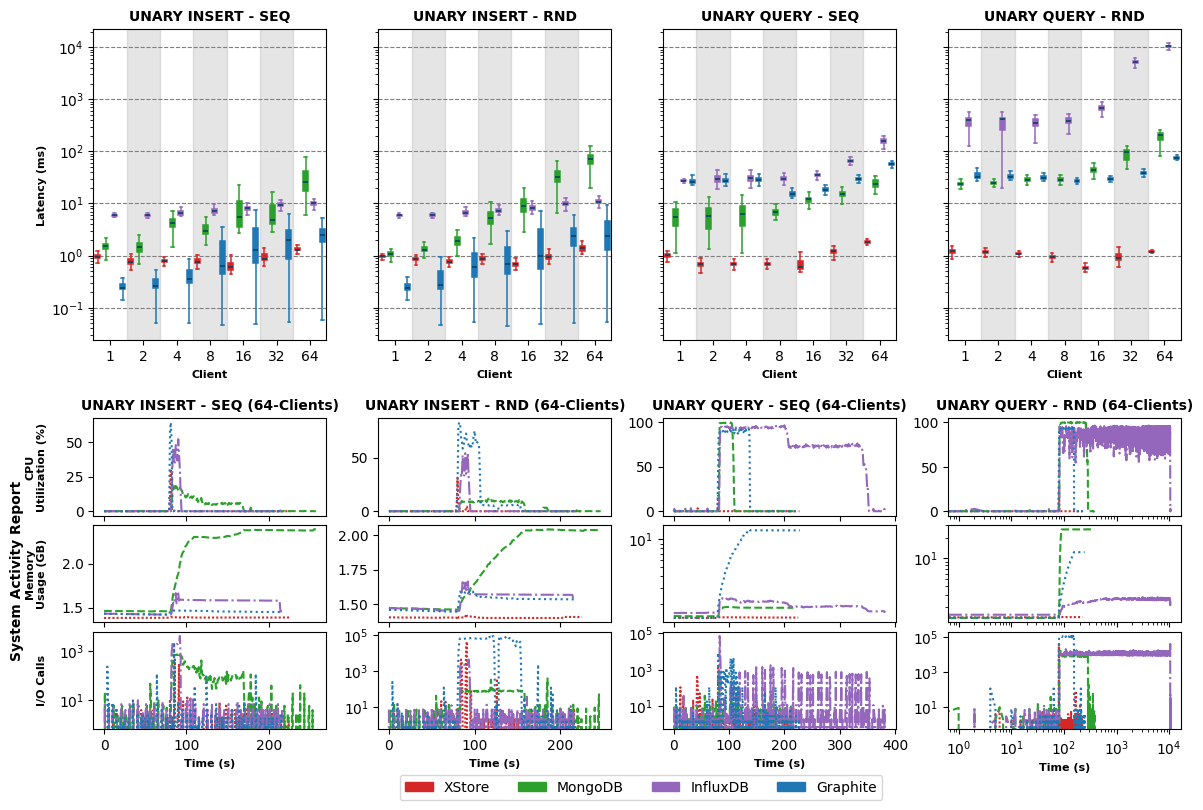

In [50]:
latencyTable, resourceTable = plotLatency(["INSERT_UNARY_SEQ", "INSERT_UNARY_RAND", "QUERY_UNARY_SEQ", "QUERY_UNARY_RAND"], f"{systemName}_latencyNumerical.svg", 7, clientNodes, logScale=True)
display(latencyTable)
display(resourceTable)


# Analytical Queries

XStore  MongoDB  InfluxDB  Graphite
Workload      Client                                          
AGG_MIN_QUERY Client-1       1.71    20.03      6.43      4.59
              Client-2       1.53    20.27      6.51      4.85
              Client-4       1.42    22.79      6.31      4.64
              Client-8       1.50    24.96      5.48      3.57
              Client-16      1.30    41.05      5.67      4.35
              Client-32      1.63    89.92     30.05      5.93
              Client-64      3.02   193.86     64.03      9.13
              AVG            1.73    58.98     17.78      5.29
              Speedup (x)    1.00    34.05     10.27      3.06

XStore      MongoDB   InfluxDB  Graphite
Workload      Metric                                                             
AGG_MIN_QUERY Memory (MB)                269.21    25,472.73     439.61    589.68
              I/O Calls               76,214.94 1,810,709.66 882,234.77 75,570.98
              CPU (s)                      5.00       214.00      74.00     11.00
              Memory (MB) Speedup (x)      1.00        94.62       1.63      2.19
              I/O Calls Speedup (x)        1.00        23.76      11.58      0.99
              CPU (s) Speedup (x)          1.00        42.80      14.80      2.20

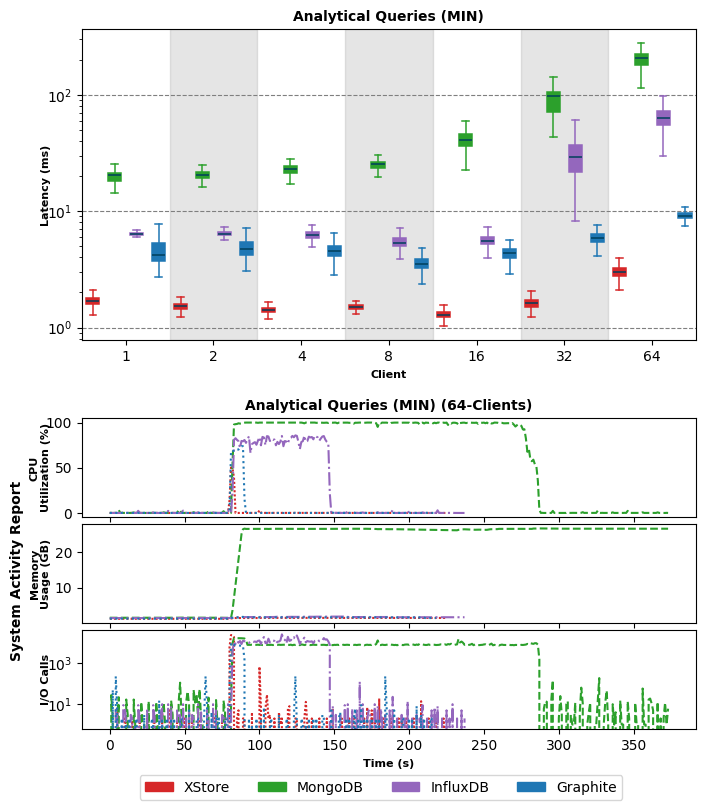

In [49]:
latencyTable, resourceTable = plotLatency(["AGG_MIN_QUERY"], f"{systemName}_analyticalQueries.svg", 7, clientNodes)
display(latencyTable)
display(resourceTable)


# Throughput

In [31]:
def plotThroughput(stopAtMultiple, clientNodes, batchSize=1000, logScale=False):
    lineWidth = 1.5
    lineAlpha = 1
    yLabelCoords = [-0.2, 0.5]
    numClients = [2**i for i in range(stopAtMultiple)]
    allData = {}

    def format_func_thousands_millions(value, tick_number):
        if value // 1000 > 0 and value < 1000000:
            return f'{int(value / 1000)}K'
        elif value // 1000000 > 0:
            value = value / 1000000
            return f'{int(value)}M' if value == int(value) else f'{value}M'
        return 0

    for WORKLOAD_TYPE in ["INSERT_BATCH_SEQ", "INSERT_BATCH_RAND", "QUERY_BATCH_SEQ", "QUERY_BATCH_RAND"]:
        temp = {}
        if WORKLOAD_TYPE in ["QUERY_BATCH_SEQ", "QUERY_BATCH_RAND"]:
            batchSize = 100

        for db in DB_LIST:
            if db in ["INFLUXDB", "GRAPHITE"] and WORKLOAD_TYPE == "QUERY_BATCH_RAND":
                continue

            clientDir = sorted([i for i in os.listdir(f"{DB_DIR[db]}/{db}_{WORKLOAD_TYPE}")], key=lambda x:int(x.split("-")[-1]))
            benchData = {}

            for idx, i in enumerate(clientDir):
                if int(i.split('-')[1]) > 64:
                    continue
                currCSVdata = []
                currClientDir = [cDir for cDir in os.listdir(f"{DB_DIR[db]}/{db}_{WORKLOAD_TYPE}/{i}")]

                for nodeIdx, item in enumerate(currClientDir):
                    myDir = f"{DB_DIR[db]}/{db}_{WORKLOAD_TYPE}/{i}/{item}"
                    csvFiles = os.listdir(myDir)
                    csvFiles = [csvFile for csvFile in csvFiles if csvFile.endswith(".csv")]

                    for csvFile in csvFiles:
                        df = pd.read_csv(f'{myDir}/{csvFile}')
                        currCSVdata.append(df['Time taken (ms)'].tolist())
                df = pd.DataFrame(zip(*currCSVdata))

                 # If has value 0 -> Test must be partially/fully timed-out
                if (df.values == 0).any():
                    df['Mean'] = 0
                    benchData[i] = df['Mean'].tolist()
                    continue

                # Otherwise, compute avg. time taken across all clients
                df['Mean'] = df.mean(axis=1)
                benchData[i] = df['Mean'].tolist()

            df = pd.DataFrame(benchData)
            aggThroughput = []
            for idx, i in enumerate(df.columns):
                currDF = df[i]
                # Rows/sec = (1000ms/s / mean ms per batch) * batchSize rows/batch; x numClient for aggregate cluster throughput
                numClient = int(i.split("-")[-1])
                if currDF.mean() == 0:
                    aggThroughput.append(0)
                else:
                    aggThroughput.append(round(1000 * batchSize / currDF.mean() * numClient))
            temp[db] = aggThroughput
        allData[WORKLOAD_TYPE] = temp

    fig = plt.figure(figsize=(12, 7))
    subFigs = fig.subfigures(2, 1, hspace=0.25)
    axs = subFigs[0].subplots(1, 4)
    axss = subFigs[1].subplots(3, 4)
    subFigs[1].subplots_adjust(hspace=0.1, wspace=0.175)

    x = np.arange(len(numClients))  # the label locations
    width = 0.21  # the width of the bars

    throughputTables = {}
    for idx, workload in enumerate(allData):
        multiplier = 0
        dbList = list(DB_LIST)
        if "INFLUXDB" not in allData[workload]:
            allData[workload]["INFLUXDB"] = [0 for i in enumerate(clientDir)]
            dbList = ["XSTORE", "MONGODB"]
        if "GRAPHITE" not in allData[workload]:
            allData[workload]["GRAPHITE"] = [0 for i in enumerate(clientDir)]
            dbList = ["XSTORE", "MONGODB"]

        for db in dbList:
            offset = width * multiplier
            axs[idx].bar(x + offset, allData[workload][db], width, label=DB_LABEL[db], color=DB_COLOR[db])
            axs[idx].set_yscale('log')
            multiplier += 1

        s = workload.split('_')
        axs[idx].set_title(f"{s[1]} {s[0]} - {s[-1].replace('RAND', 'RND')}", fontweight="bold", fontsize=10)
        axs[idx].set_xticks(x + width + 0.08, numClients)
        axs[idx].set_xlabel(xlabel="Client", fontweight="bold", fontsize=8)
        axs[idx].grid(axis="y", which="major", linestyle="--", color="tab:gray")

        # Per-client-tier throughput table for this workload (Backtester-style: rows=Client-N, cols=DB)
        tierData = {DB_LABEL["XSTORE"]: allData[workload]["XSTORE"], "MongoDB": allData[workload]["MONGODB"]}
        if "INFLUXDB" in dbList:
            tierData["InfluxDB"] = allData[workload]["INFLUXDB"]
        if "GRAPHITE" in dbList:
            tierData["Graphite"] = allData[workload]["GRAPHITE"]
        tierTable = pd.DataFrame(tierData, index=[f"Client-{n}" for n in numClients])
        tierTable.loc["AVG"] = tierTable.mean()
        # Speedup = how many times better XStore is (higher throughput = better): >1 means XStore
        # is faster by that factor, <1 means XStore is actually slower (by 1/x).
        tierTable.loc["Speedup (x)"] = tierTable.loc["AVG", DB_LABEL["XSTORE"]] / tierTable.loc["AVG"]
        throughputTables[workload] = tierTable

        if logScale:
            axs[idx].set_yscale('log')
        axs[idx].margins(y=0.1)

    axs[0].set_ylabel(ylabel="Throughput (Rows/s)", fontweight="bold", fontsize=9)
    axs[0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])
    for ax in axs[1:]:
        ax.sharey(axs[0])
        ax.tick_params(labelleft=False)

    # Sysstat (resource usage @ Client-64)
    allData = {}
    for WORKLOAD_TYPE in ["INSERT_BATCH_SEQ", "INSERT_BATCH_RAND", "QUERY_BATCH_SEQ", "QUERY_BATCH_RAND"]:
        temp = {}
        for db in DB_LIST:
            if WORKLOAD_TYPE == "QUERY_BATCH_RAND" and db in ["INFLUXDB", "GRAPHITE"]:
                continue
            temp[db] = load_sysstat_data(db, WORKLOAD_TYPE)
        allData[WORKLOAD_TYPE] = temp

    resourceTables = {}
    for idx, workload in enumerate(allData):
        for db in DB_LIST:
            if db not in allData[workload]:
                continue
            axss[0][idx].plot(allData[workload][db]["Client-64"]["CPU Utilization (%)"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], label=DB_LABEL[db], linewidth=lineWidth, alpha=lineAlpha)
            axss[1][idx].plot(allData[workload][db]["Client-64"]["Memory Usage (GB)"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], linewidth=lineWidth, alpha=lineAlpha)
            axss[2][idx].plot(allData[workload][db]["Client-64"]["I/O Calls"], ls=DB_LINESTYLE[db], color=DB_COLOR[db], linewidth=lineWidth, alpha=lineAlpha)

        s = workload.split('_')
        axss[0][idx].set_title(f"{s[1]} {s[0]} - {s[-1].replace('RAND', 'RND')} (64-Clients)", fontweight="bold", fontsize=10)
        axss[2][idx].set_xlabel(xlabel="Time (s)", fontweight="bold", fontsize=8)
        axss[2][idx].yaxis.set_major_formatter(mpl.ticker.FuncFormatter(format_func_thousands_millions))
        axss[0][idx].set_xticklabels([])
        axss[1][idx].set_xticklabels([])
        axss[2][idx].set_yscale('log')
        if idx == 3:
            axss[1][idx].set_yscale('log')

        # Resource usage @ Client-64 for this workload: rows=metric, cols=DB, plus a Speedup row per
        # metric underneath. Speedup = how many times better XStore is (lower usage = better):
        # >1 means XStore uses that much less, <1 means XStore actually uses more (by 1/x).
        usage = {}
        for db in DB_LIST:
            if db not in allData[workload]:
                continue
            mem = allData[workload][db]["Client-64"]["Memory Usage (GB)"]
            io = allData[workload][db]["Client-64"]["I/O Calls"]
            cpu = allData[workload][db]["Client-64"]["CPU Utilization (%)"]
            usage[DB_LABEL[db]] = {
                "Memory (MB)": (max(mem) - min(mem)) * 1024,
                "I/O Calls": sum(io),
                "CPU (s)": len(cpu[cpu > 1]),
            }
        resourceTable = pd.DataFrame(usage)
        for metric in ["Memory (MB)", "I/O Calls", "CPU (s)"]:
            resourceTable.loc[f"{metric} Speedup (x)"] = resourceTable.loc[metric] / resourceTable.loc[metric, DB_LABEL["XSTORE"]]
        resourceTables[workload] = resourceTable

    subFigs[1].suptitle("System Activity Report", y=0.8, x=0.03, rotation=90, ha='center', va='top', fontweight="bold", fontsize=10)
    axss[0][0].set_ylabel(ylabel="CPU\nUtilization (%)", fontweight="bold", fontsize=8)
    axss[0][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])
    axss[1][0].set_ylabel(ylabel="Memory\nUsage (GB)", fontweight="bold", fontsize=8)
    axss[1][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])
    axss[2][0].set_ylabel(ylabel="I/O Calls", fontweight="bold", fontsize=8)
    axss[2][0].get_yaxis().set_label_coords(yLabelCoords[0], yLabelCoords[1])

    patches = [mpatches.Patch(color=DB_COLOR[db], label=DB_LABEL[db]) for db in DB_LIST]
    subFigs[1].legend(handles=patches, labels=[DB_LABEL[db] for db in DB_LIST], bbox_to_anchor=(0.55, -0.25), loc='lower center', ncol=4)
    plt.axis('tight')
    plt.tight_layout(pad=0)
    plt.savefig(f"{systemName}_throughputNumerical.svg", format='svg', dpi=fig.dpi, bbox_inches='tight')

    # Combine each workload's table into one DataFrame, indexed by (Workload, ...its own row label)
    throughputTable = pd.concat(throughputTables, names=["Workload", "Client"]).round(2)
    resourceTable = pd.concat(resourceTables, names=["Workload", "Metric"]).round(2)
    return throughputTable, resourceTable


XStore   MongoDB  InfluxDB  Graphite
Workload          Client                                              
INSERT_BATCH_SEQ  Client-1      2,411.00    944.00    214.00    311.00
                  Client-2      4,158.00  1,555.00    413.00    411.00
                  Client-4     10,549.00  1,784.00    805.00    666.00
                  Client-8     22,310.00  1,502.00  1,614.00  1,232.00
                  Client-16    43,214.00  1,147.00  2,937.00  2,329.00
                  Client-32    73,072.00      0.00      0.00  2,736.00
                  Client-64    98,642.00      0.00      0.00  2,460.00
                  AVG          36,336.57    990.29    854.71  1,449.29
                  Speedup (x)       1.00     36.69     42.51     25.07
INSERT_BATCH_RAND Client-1      1,598.00    133.00    215.00    272.00
                  Client-2      3,386.00      0.00    436.00    636.00
                  Client-4      7,330.00      0.00    781.00  1,589.00
                  Client-8     13,717.00      0.00  1,611.00  3,138.00
                  Client-16    25,519.00      0.00  2,695.00  4,380.00
                  Client-32    38,788.00      0.00      0.00  4,834.00
                  Client-64    34,406.00      0.00      0.00  6,071.00
                  AVG          17,820.57     19.00    819.71  2,988.57
                  Speedup (x)       1.00    937.92     21.74      5.96
QUERY_BATCH_SEQ   Client-1      6,909.00  2,935.00    197.00    900.00
                  Client-2     14,388.00  4,336.00    385.00  1,736.00
                  Client-4     29,550.00 10,352.00    801.00  3,425.00
                  Client-8     55,350.00 17,420.00  1,453.00  7,774.00
                  Client-16   108,668.00 27,794.00  2,301.00 15,998.00
                  Client-32   169,707.00 43,883.00    679.00 26,060.00
                  Client-64   272,617.00 47,443.00    691.00 32,548.00
                  AVG          93,884.14 22,023.29    929.57 12,634.43
                  Speedup (x)       1.00      4.26    101.00      7.43
QUERY_BATCH_RAND  Client-1      4,155.00     36.00       NaN       NaN
                  Client-2      8,634.00     69.00       NaN       NaN
                  Client-4     19,335.00    136.00       NaN       NaN
                  Client-8     38,043.00    232.00       NaN       NaN
                  Client-16    72,689.00    356.00       NaN       NaN
                  Client-32   137,384.00    574.00       NaN       NaN
                  Client-64   222,971.00    660.00       NaN       NaN
                  AVG          71,887.29    294.71       NaN       NaN
                  Speedup (x)       1.00    243.92       NaN       NaN

XStore      MongoDB     InfluxDB     Graphite
Workload          Metric                                                                     
INSERT_BATCH_SEQ  Memory (MB)                 2,099.09     1,669.23    17,894.09        75.40
                  I/O Calls                   8,994.98    14,011.00    44,087.33    58,411.78
                  CPU (s)                        10.00       233.00       238.00       267.00
                  Memory (MB) Speedup (x)         1.00         0.80         8.52         0.04
                  I/O Calls Speedup (x)           1.00         1.56         4.90         6.49
                  CPU (s) Speedup (x)             1.00        23.30        23.80        26.70
INSERT_BATCH_RAND Memory (MB)                 2,092.99     3,630.14    17,510.75       289.30
                  I/O Calls               1,206,102.91       850.00    25,566.98 8,982,951.17
                  CPU (s)                        27.00       217.00       239.00       163.00
                  Memory (MB) Speedup (x)         1.00         1.73         8.37         0.14
                  I/O Calls Speedup (x)           1.00         0.00         0.02         7.45
                  CPU (s) Speedup (x)             1.00         8.04         8.85         6.04
QUERY_BATCH_SEQ   Memory (MB)                    67.25     4,231.44       748.99     1,021.27
                  I/O Calls                   1,666.92    20,112.00 1,135,615.50    93,595.96
                  CPU (s)                         2.00         3.00       106.00         3.00
                  Memory (MB) Speedup (x)         1.00        62.92        11.14        15.19
                  I/O Calls Speedup (x)           1.00        12.07       681.27        56.15
                  CPU (s) Speedup (x)             1.00         1.50        53.00         1.50
QUERY_BATCH_RAND  Memory (MB)                    28.52    27,194.96          NaN          NaN
                  I/O Calls                  21,123.98 1,135,814.91          NaN          NaN
                  CPU (s)                         1.00       110.00          NaN          NaN
                  Memory (MB) Speedup (x)         1.00       953.43          NaN          NaN
                  I/O Calls Speedup (x)           1.00        53.77          NaN          NaN
                  CPU (s) Speedup (x)             1.00       110.00          NaN          NaN

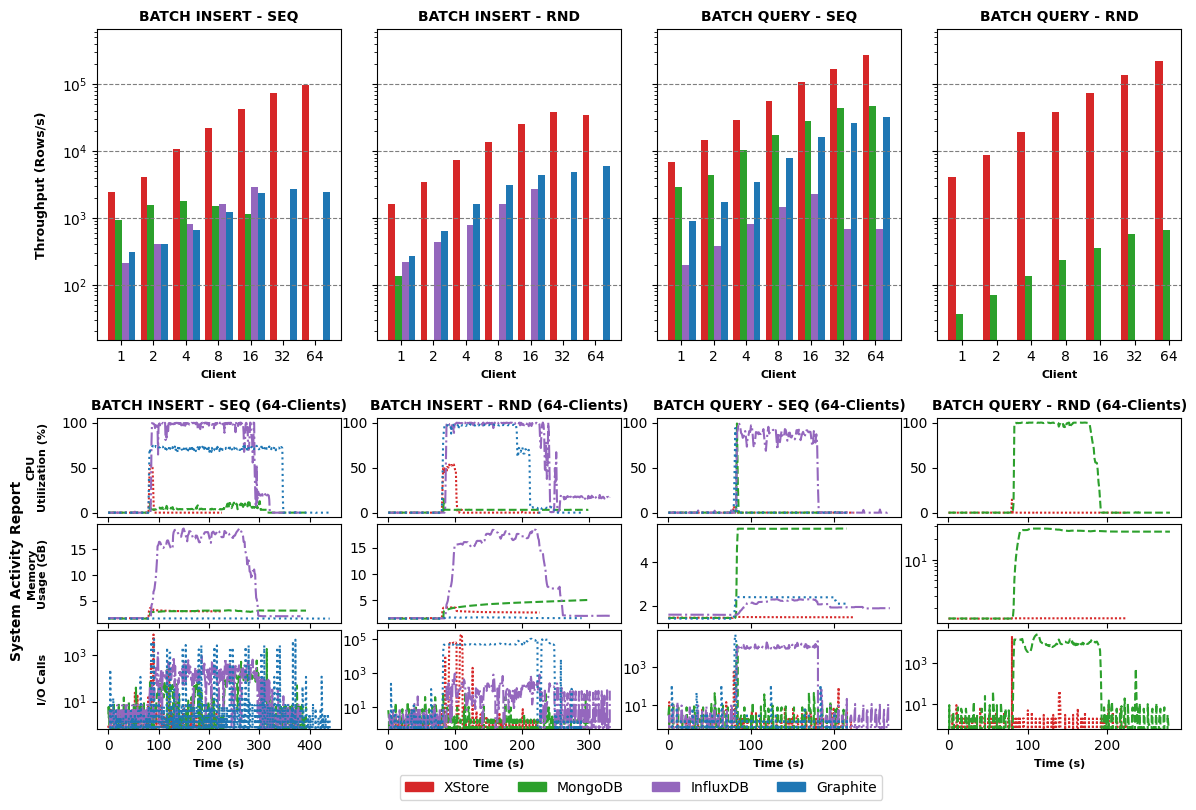

In [32]:
throughputTable, resourceTable = plotThroughput(7, clientNodes, batchSize=1000)
display(throughputTable)
display(resourceTable)
